## Loading Data

In [2]:
import pandas as pd
import re
import math
import numpy as np
from urllib.parse import urlparse
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from rf_finetuned_feature_extraction import extract_features_vectorized, load_trusted_domains
from sklearn.metrics import precision_recall_curve, classification_report, confusion_matrix
from joblib import dump, load
%pip install shap
import shap
from collections import Counter
import tldextract
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.inspection import PartialDependenceDisplay, partial_dependence
import sys
import os


RF Pretuned feature extraction module loaded. Expected features: 49
Note: you may need to restart the kernel to use updated packages.


In [3]:
df = pd.read_csv('/Users/abdulsalamali/School/Dissertation/datasets/Dataset3.csv')
urls = df['url']
df

,url,status
0,http://modelsnext.com/doc/mgs/es/index.php,1
1,alacrastore.com/research/thomson-streetevents-...,0
2,fallingrain.com/icao/WIMT.html,0
3,liveleak.com/view?i=c40_1308381371,0
4,bid.lowercanadaauction.com/Canadian-Coin-Aucti...,0
...,...,...
874653,13453765871837679316.googlegroups.com/attach/5...,1
874654,docstoc.com/docs/49594266/Visiting-Team-Guide-...,0
874655,yank.sourceforge.net/index.html,0
874656,microsoftloginonline.dynu.net,1


In [4]:
def load_trusted_domains(csv_path='/Users/abdulsalamali/School/Dissertation/datasets/trusted_domains.csv'):
    """Load and normalize trusted domains from CSV file."""
    try:
        df = pd.read_csv(csv_path)
        domains = set()
        for url_str in df['url'].dropna():
            url_str = str(url_str).strip().lower()
            # Extract domain if URL has a scheme (e.g., "https://google.com")
            if '://' in url_str:
                parsed = urlparse(url_str)
                domain = parsed.netloc
            else:
                domain = url_str
            # Remove port if present
            if ':' in domain:
                domain = domain.split(':')[0]
            domains.add(domain)
        return domains
    except FileNotFoundError:
        print(f"Warning: Trusted domains file '{csv_path}' not found. Using default trusted domains.")
        return {'youtube.com', 'wikipedia.org', 'github.com', 'google.com', 'microsoft.com'}

In [5]:
# Vectorized feature extraction 
trusted_domains_set = load_trusted_domains()

features_df = extract_features_vectorized(df['url'], trusted_domains_set)
features_df['status'] = df['status'].values

print(f"Feature extraction completed: {len(features_df.columns)-1} features extracted")
print(f"Dataset shape: {features_df.shape}")
features_df.head()

Feature extraction completed: 49 features extracted
Dataset shape: (874658, 50)


,url_length,domain_length,is_trusted_domain,is_trusted_subdomain,num_dots,num_hyphens,num_slashes,num_digits,domain_dots,domain_hyphens,...,special_char_ratio,digit_to_letter_ratio,char_variety,domain_char_variety,entropy_url,entropy_domain,entropy_path,has_non_ascii,long_numeric_sequence,status
0,42,14,0,0,2,0,6,0,1,0,...,0.0,0.000000,0.404762,0.785714,3.915196,3.378783,3.630413,1,0,1
1,110,0,0,0,1,3,2,7,0,0,...,0.0,0.076923,0.263636,0.000000,4.647140,0.000000,4.647140,0,0,0
2,30,0,0,0,2,0,2,0,0,0,...,0.0,0.000000,0.500000,0.000000,4.031402,0.000000,4.031402,0,0,0
3,34,0,0,0,1,0,1,12,0,0,...,0.0,0.666667,0.617647,0.000000,4.233947,0.000000,3.454822,0,0,0
4,59,0,0,0,2,2,1,6,0,0,...,0.0,0.127660,0.423729,0.000000,4.365966,0.000000,4.365966,0,0,0


## Data Preparation

In [6]:
y = features_df['status']
x = features_df.drop('status', axis=1)
y

0         1
1         0
2         0
3         0
4         0
         ..
874653    1
874654    0
874655    0
874656    1
874657    0
Name: status, Length: 874658, dtype: int64

## Train/Test Split

In [7]:
# x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)
# y.value_counts()

# Data splitting 

# separate test set (15% of total data)
X_temp, X_test, y_temp, y_test = train_test_split(
    x, y, test_size=0.15, random_state=42, stratify=y
)

# separate training and validation sets from remaining data
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.2, random_state=42, stratify=y_temp  
)

print(f"Training set: {X_train.shape}, {Counter(y_train)}")
print(f"Validation set: {X_val.shape}, {Counter(y_val)}")
print(f"Test set: {X_test.shape}, {Counter(y_test)}")

# For backward compatibility 
x_train, x_test, y_train, y_test = X_train, X_test, y_train, y_test
x_val, y_val = X_val, y_val

Training set: (594767, 49), Counter({1: 304388, 0: 290379})
Validation set: (148692, 49), Counter({1: 76097, 0: 72595})
Test set: (131199, 49), Counter({1: 67145, 0: 64054})


## Model Building

### Random Forest


In [13]:

best_rf = RandomForestClassifier(
    n_estimators=150,
    max_depth=30,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight={0: 1.5, 1: 1},  # Penalize false positives
    n_jobs=-1,
    random_state=42
)
best_rf.fit(x_train, y_train)





RandomForestClassifier(class_weight={0: 1.5, 1: 1}, max_depth=30,
                       min_samples_leaf=2, min_samples_split=5,
                       n_estimators=150, n_jobs=-1, random_state=42)

In [14]:
best_rf.n_estimators = 200  # Add more trees
best_rf.fit(x_train, y_train)  # Warm start

RandomForestClassifier(class_weight={0: 1.5, 1: 1}, max_depth=30,
                       min_samples_leaf=2, min_samples_split=5,
                       n_estimators=200, n_jobs=-1, random_state=42)

In [ ]:
# Save model

dump(best_rf, 'rf_test_finetuned.joblib')

['rf_test_pretuned.joblib']

In [8]:
from joblib import load

# Load the model
loaded_model = load('/Users/abdulsalamali/School/Dissertation/final/rf_test_finetuned.joblib') 
trusted_domains = load_trusted_domains()


In [9]:
y_proba = loaded_model.predict_proba(x_test)[:, 1]  # Probabilities for phishing class

# Find optimal threshold for precision
precision, recall, thresholds = precision_recall_curve(y_test, y_proba)
target_precision = 0.985
optimal_threshold = thresholds[np.argmax(precision >= target_precision)]

print(f"Optimal threshold: {optimal_threshold:.4f}")


y_pred_adjusted = (y_proba >= optimal_threshold).astype(int) 

Optimal threshold: 0.6355


In [10]:
# To see how both thresholds work
from sklearn.metrics import precision_score, recall_score

for threshold in [0.6355, 0.1]:
    y_pred = (y_proba >= threshold).astype(int)
    print(f"\nThreshold: {threshold:.4f}")
    print(f"Precision: {precision_score(y_test, y_pred):.4f}")
    print(f"Recall: {recall_score(y_test, y_pred):.4f}")
    print(f"False Positives: {((y_pred == 1) & (y_test == 0)).sum()}")
    print(f"False Negatives: {((y_pred == 0) & (y_test == 1)).sum()}")


Threshold: 0.6355
Precision: 0.9850
Recall: 0.8882
False Positives: 909
False Negatives: 7510

Threshold: 0.1000
Precision: 0.7963
Recall: 0.9830
False Positives: 16880
False Negatives: 1141


In [11]:
threshold = 0.6355
human_review_lower = 0.1
human_review_upper = threshold

y_proba = loaded_model.predict_proba(x_test)[:, 1]  # Probabilities for phishing class

y_pred_auto = (y_proba >= threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_auto).ravel()

phishing_indices = np.where(y_test == 1)[0]
phishing_probs = y_proba[phishing_indices]
missed_phishing = np.sum(phishing_probs < human_review_lower)
actual_fnr = missed_phishing / len(phishing_indices)

human_review_phishing = np.sum((phishing_probs >= human_review_lower) & (phishing_probs < threshold))

print(f"FPR: {fp/(fp+tn):.4f}")
print(f"initial FNR: {fn/(fn+tp):.4f}")
print(f"FNR after human review: {actual_fnr:.4f}")
print(f"human Review Workload: {((y_proba >= human_review_lower) & (y_proba < human_review_upper)).mean():.2%}")

FPR: 0.0142
initial FNR: 0.1118
FNR after human review: 0.0170
human Review Workload: 17.03%


AUC (Validation): 0.9838
AUC (Test): 0.9842


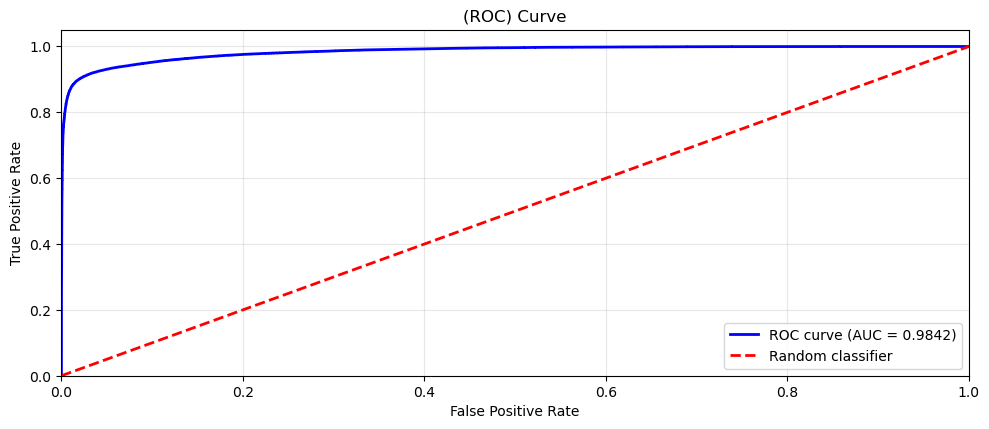

In [12]:
# Calculate AUC 
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

auc_score = roc_auc_score(y_test, y_proba)

y_proba_val = loaded_model.predict_proba(x_val)[:, 1]
auc_score_val = roc_auc_score(y_val, y_proba_val)
print(f"AUC (Validation): {auc_score_val:.4f}")
print(f"AUC (Test): {auc_score:.4f}")
# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_proba)

# Plotcurve
plt.figure(figsize=(10, 8))
plt.subplot(2, 1, 1)
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--', label='Random classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('(ROC) Curve')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)


plt.tight_layout()
plt.show()



In [13]:
def calculate_metrics_with_thresholds(y_true, y_proba, lower_threshold, upper_threshold):

    predictions = np.full(len(y_proba), 'human_review')
    predictions[y_proba <= lower_threshold] = 'legitimate'
    predictions[y_proba >= upper_threshold] = 'phishing'
    
    legitimate_mask = (y_true == 0)
    phishing_mask = (y_true == 1)

    legitimate_predicted_phishing = np.sum((predictions == 'phishing') & legitimate_mask)
    legitimate_total = np.sum(legitimate_mask)
    fpr = legitimate_predicted_phishing / legitimate_total if legitimate_total > 0 else 0

    phishing_predicted_legitimate = np.sum((predictions == 'legitimate') & phishing_mask)
    phishing_total = np.sum(phishing_mask)
    fnr = phishing_predicted_legitimate / phishing_total if phishing_total > 0 else 0

    human_review_count = np.sum(predictions == 'human_review')
    human_review_rate = human_review_count / len(predictions)
    
    return {
        'fpr': fpr,
        'fnr': fnr, 
        'human_review_rate': human_review_rate,
        'predictions': predictions
    }


y_proba =  loaded_model.predict_proba(X_val)[:, 1]

# Test multiple threshold combinations for XGBoost
print("Threshold analysis:")
print("\n")

threshold_options = [
    (0.14, 0.76, "Balanced Production"),
    (0.12, 0.78, "High accuracy"),
    (0.18, 0.72, "High efficiency"),
    (0.10, 0.6355, "98.5% precision)"),
]

print(f"{'Thresholds':<15} {'FPR':<8} {'FNR':<8} {'HR':<8} {'Auto%':<8} {'Description'}")

for lower, upper, description in threshold_options:
    metrics = calculate_metrics_with_thresholds(y_val, y_proba, lower, upper)
    automation_rate = 1 - metrics['human_review_rate']
    
    print(f"{lower:.2f}/{upper:.2f}    {metrics['fpr']*100:>6.1f}% {metrics['fnr']*100:>6.1f}% {metrics['human_review_rate']*100:>6.1f}% {automation_rate*100:>6.1f}%   {description}")

Threshold analysis:


Thresholds      FPR      FNR      HR       Auto%    Description
0.14/0.76       0.9%    2.9%   13.7%   86.3%   Balanced Production
0.12/0.78       0.9%    2.3%   16.2%   83.8%   High accuracy
0.18/0.72       1.1%    4.3%    9.8%   90.2%   High efficiency
0.10/0.64       1.5%    1.7%   16.9%   83.1%   98.5% precision)


#### 1. Global Feature Importance

Feature importnace analysis
                  Feature  Importance
6             num_slashes    0.167767
46           entropy_path    0.075504
33        url_path_length    0.069633
35       first_dir_length    0.063560
37        suspicious_path    0.050895
17           double_slash    0.046084
18       has_double_slash    0.044942
39            alpha_ratio    0.038182
43    domain_char_variety    0.034464
1           domain_length    0.028818
45         entropy_domain    0.028274
44            entropy_url    0.027417
7              num_digits    0.025975
4                num_dots    0.025712
0              url_length    0.024018
20   has_suspicious_words    0.023649
5             num_hyphens    0.022767
2       is_trusted_domain    0.022240
47          has_non_ascii    0.020021
34             path_depth    0.019928
42           char_variety    0.017843
38            digit_ratio    0.017547
41  digit_to_letter_ratio    0.016439
8             domain_dots    0.015892
12         num_subdoma

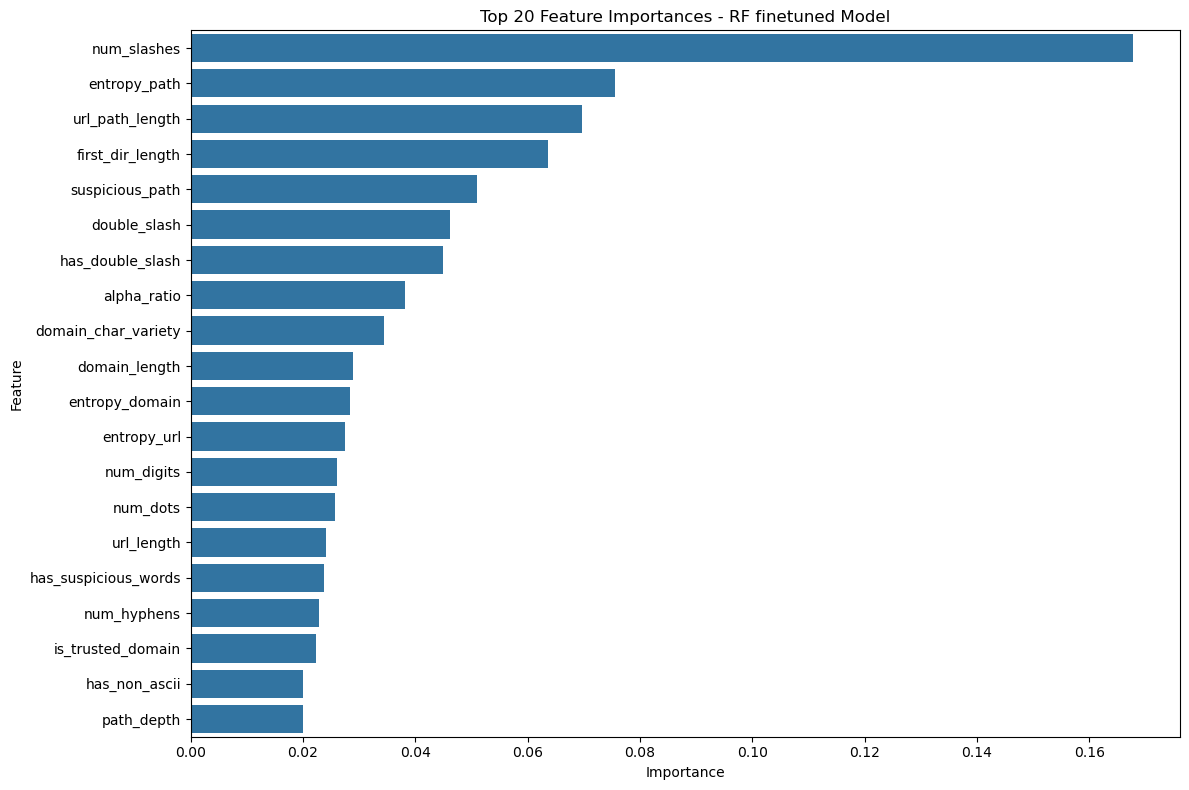

In [14]:
print("Feature importnace analysis")

feature_importances = loaded_model.feature_importances_
features = x_train.columns

importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': feature_importances
}).sort_values('Importance', ascending=False)

print(importance_df)

plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=importance_df.head(20))
plt.title('Top 20 Feature Importances - RF finetuned Model')
plt.tight_layout()
plt.savefig('finetuned_feature_importance.png')
plt.show()

#### 2. Feature Contribution to False Positives


False positives analysis


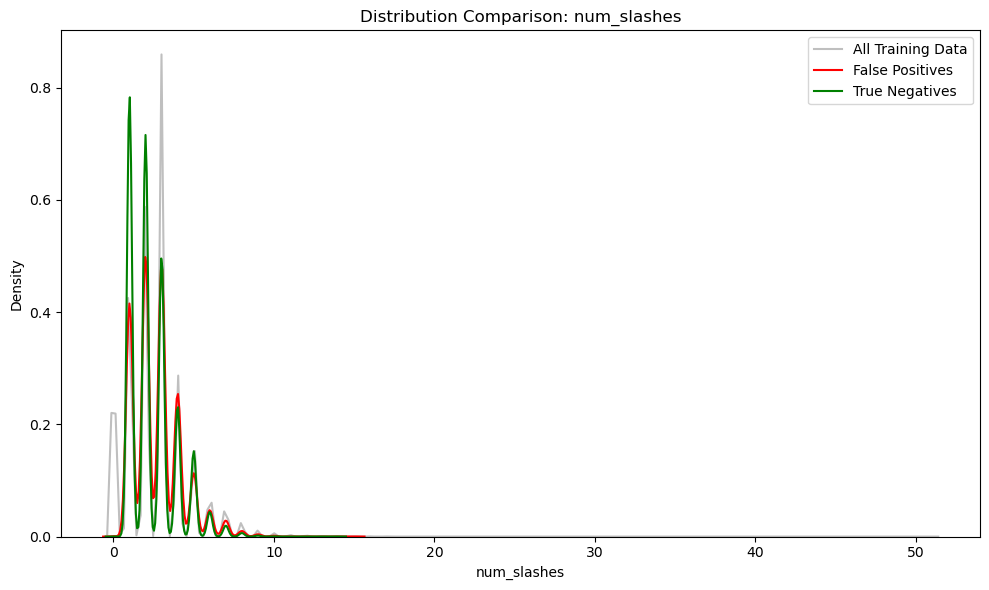

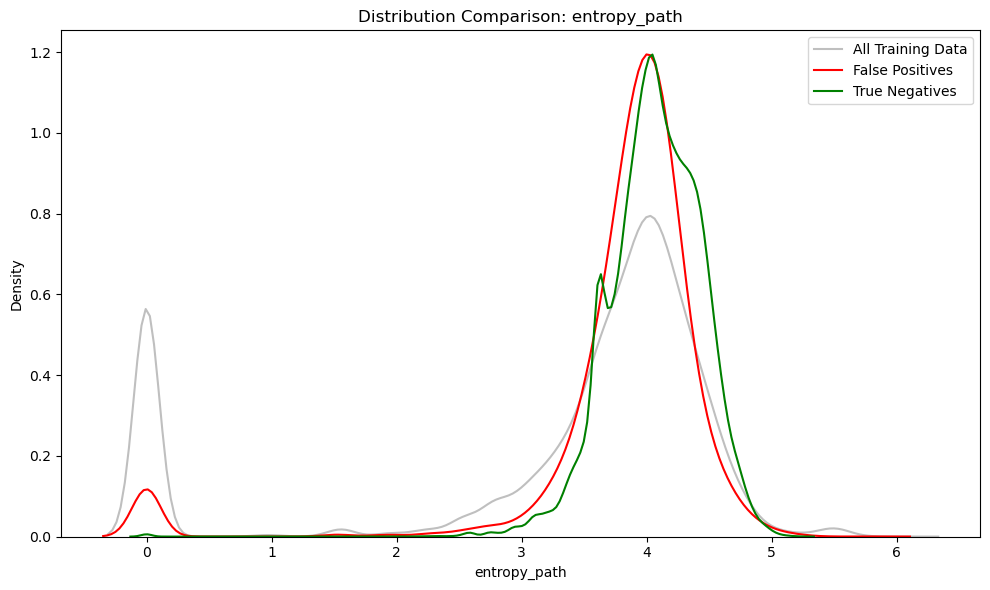

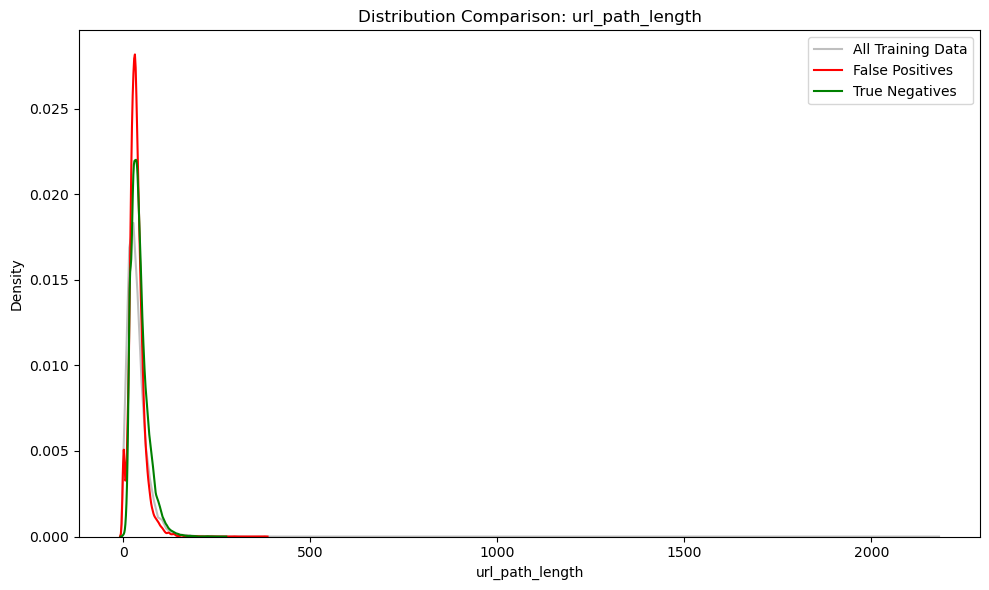

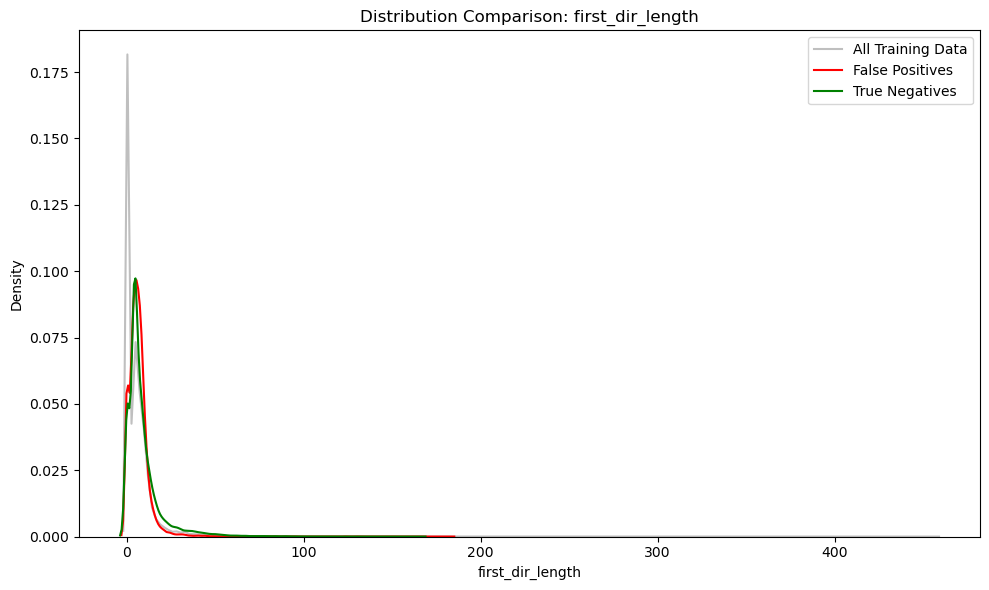

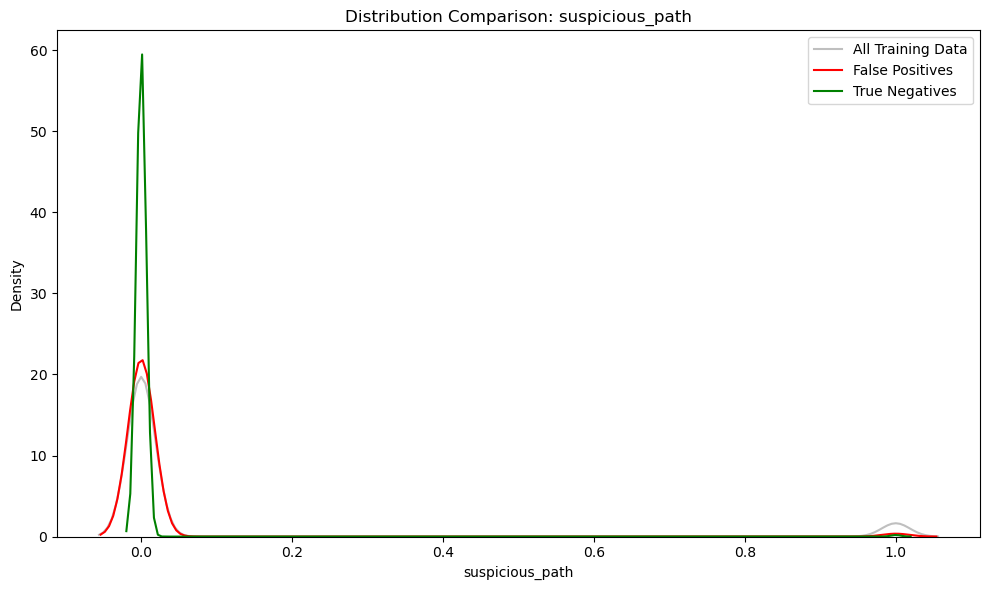

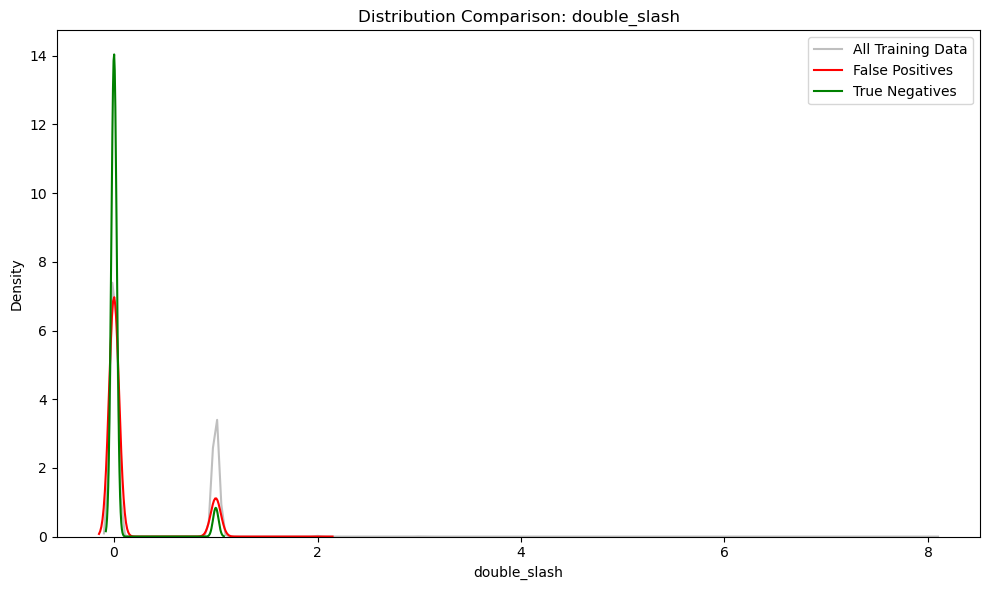

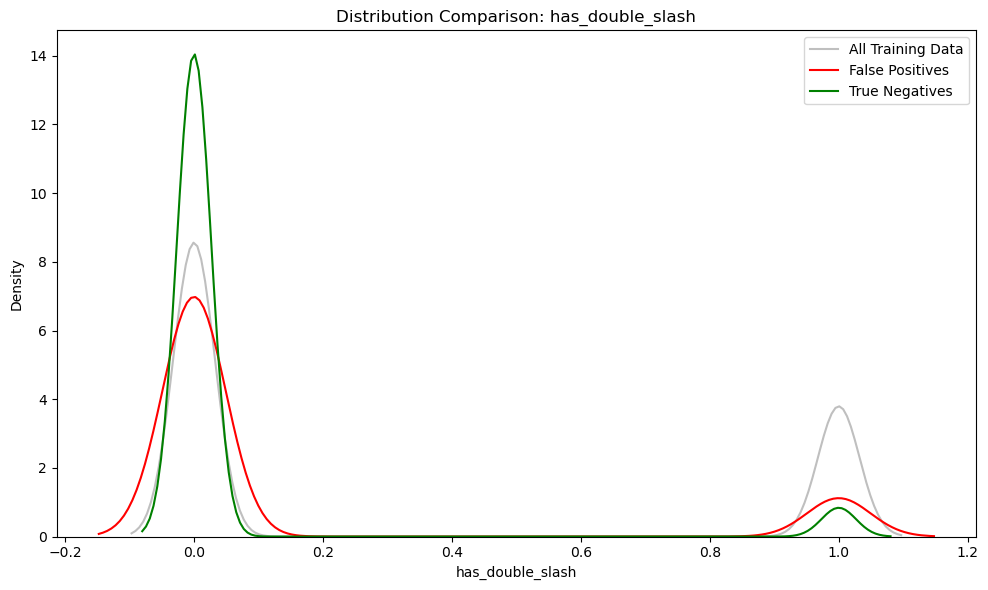

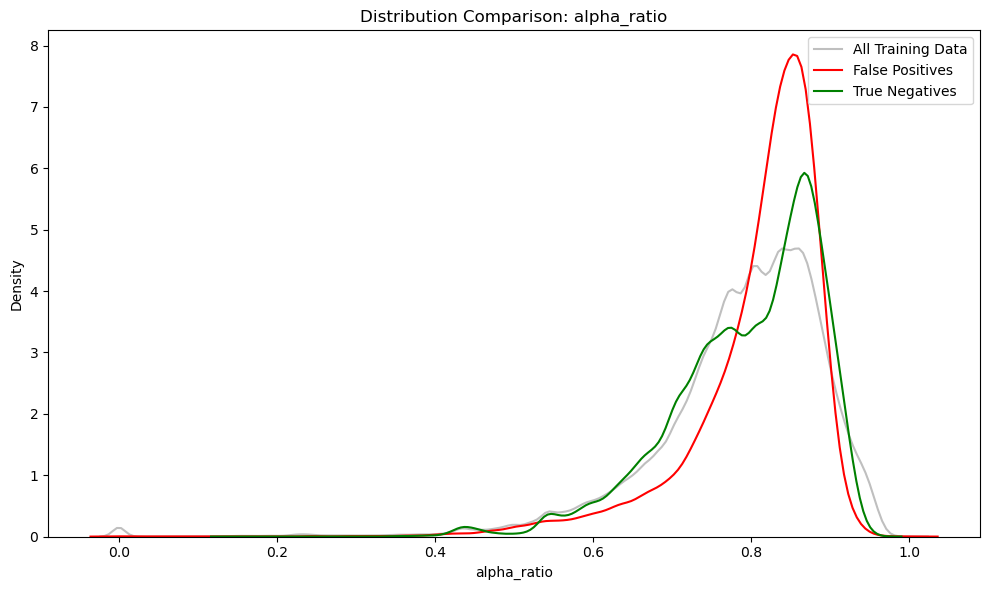

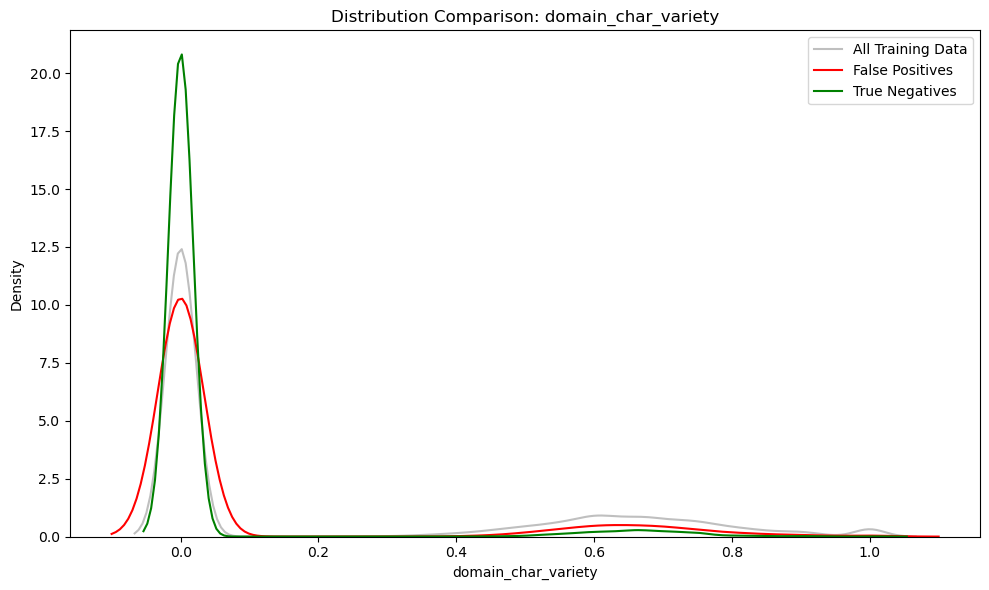

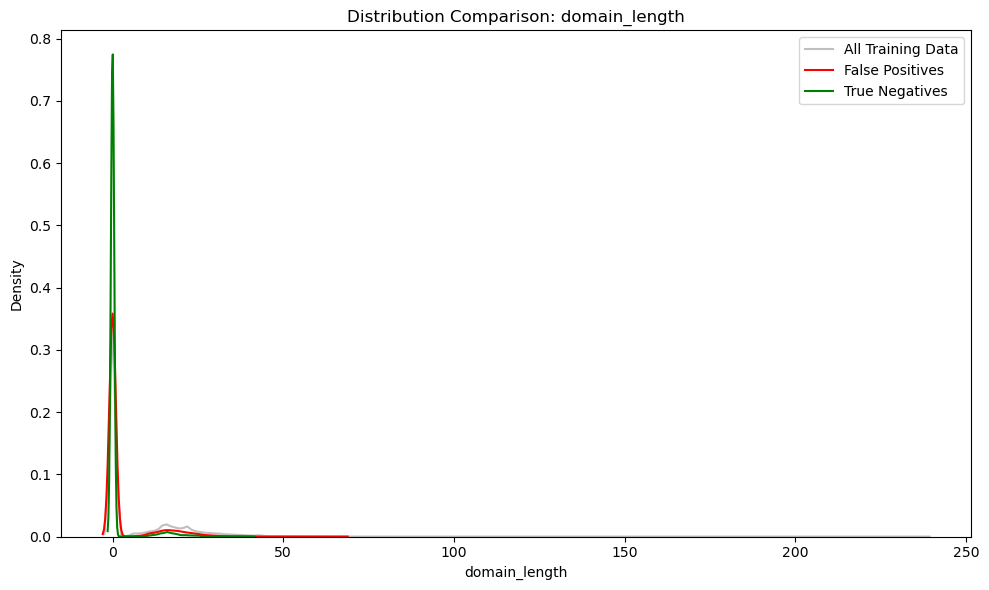

In [15]:
print("False positives analysis")

fp_mask = (y_pred == 1) & (y_test == 0)
fp_data = x_test[fp_mask]
fp_count = fp_mask.sum()

if fp_count > 0:

    def compare_distributions(feature):
        plt.figure(figsize=(10, 6))
  
        sns.kdeplot(x_train[feature], label='All Training Data', color='grey', alpha=0.5)
    
        if len(fp_data) > 1:
            sns.kdeplot(fp_data[feature], label='False Positives', color='red')
  
        tn_mask = (y_pred == 0) & (y_test == 0)
        tn_data = x_test[tn_mask]
        if len(tn_data) > 1:
            sns.kdeplot(tn_data[feature], label='True Negatives', color='green')
        
        plt.title(f'Distribution Comparison: {feature}')
        plt.legend()
        plt.tight_layout()
        plt.savefig(f'finetuned_fp_distribution_{feature.replace("/", "_")}.png')
        plt.show()

    for feature in importance_df['Feature'].head(10):
        compare_distributions(feature)

#### 3. Partial Dependence Plots (PDPs) for False Positives

PDPs for FPs
compatible features: 7/10


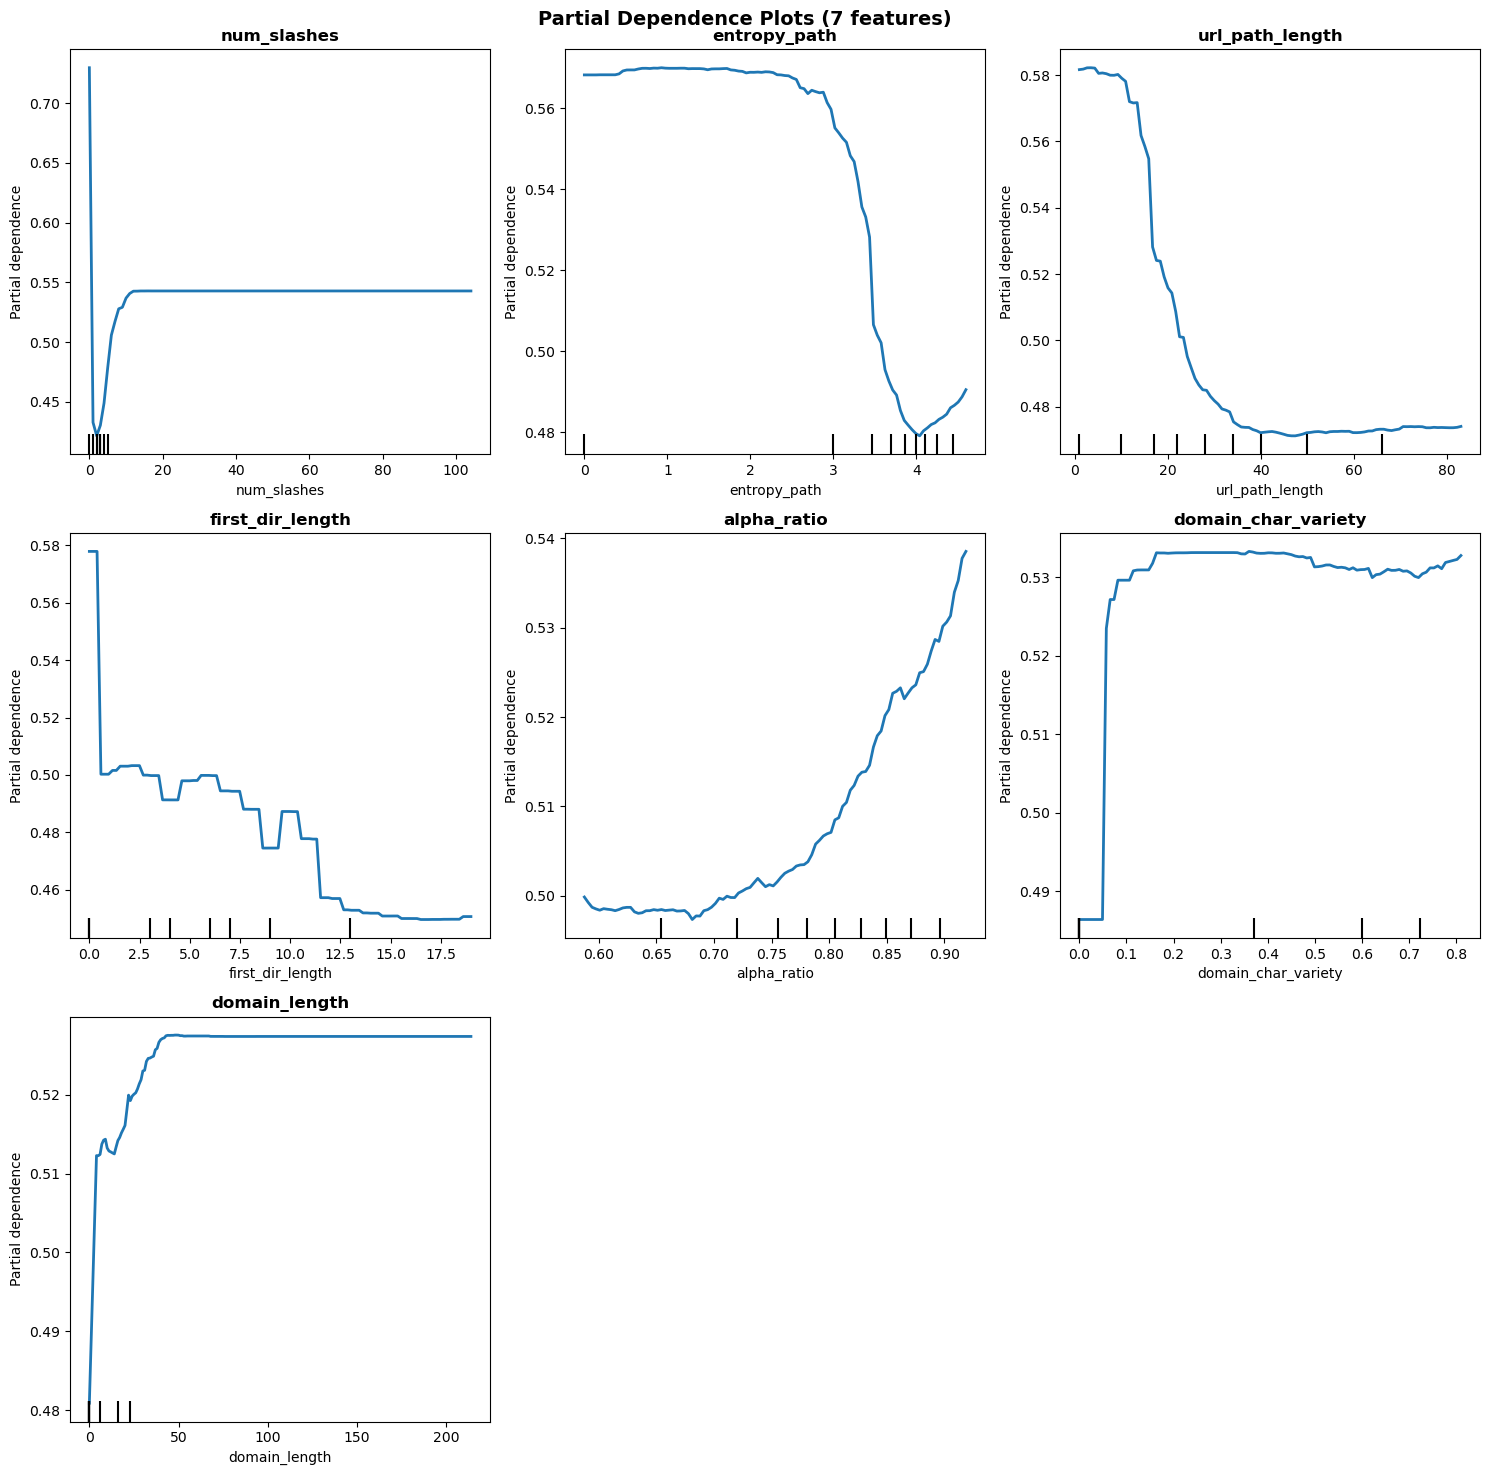

In [22]:
print("PDPs for FPs")

def is_pdp_safe(model, X, feature_name):
    try:
        from sklearn.inspection import partial_dependence
        feature_idx = list(X.columns).index(feature_name)
        partial_dependence(model, X.iloc[:50], features=[feature_idx])
        return True
    except:
        return False

top_features = importance_df.Feature.head(10).tolist()
pdp_features = [f for f in top_features if is_pdp_safe(loaded_model, x_test, f)]

print(f"compatible features: {len(pdp_features)}/{len(top_features)}")
if not pdp_features:
    print("No compatible features")
    exit()

n_features = len(pdp_features)
n_cols = 3
n_rows = (n_features + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5*n_rows))
if n_features == 1:
    axes = [axes]
elif n_rows == 1:
    axes = axes.reshape(1, -1)
axes = axes.flatten()

for i, feature in enumerate(pdp_features):
    PartialDependenceDisplay.from_estimator(
        loaded_model,
        x_test,
        features=[feature],
        ax=axes[i],
        line_kw={'linewidth': 2}
    )
    axes[i].set_title(f'{feature}', fontweight='bold')
    axes[i].grid(True, alpha=0.3)

for i in range(n_features, len(axes)):
    axes[i].set_visible(False)

plt.suptitle(f'Partial Dependence Plots ({n_features} features)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('finetuned_fp_pdp_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

#### 4. False Negative Analysis

False negative analysis


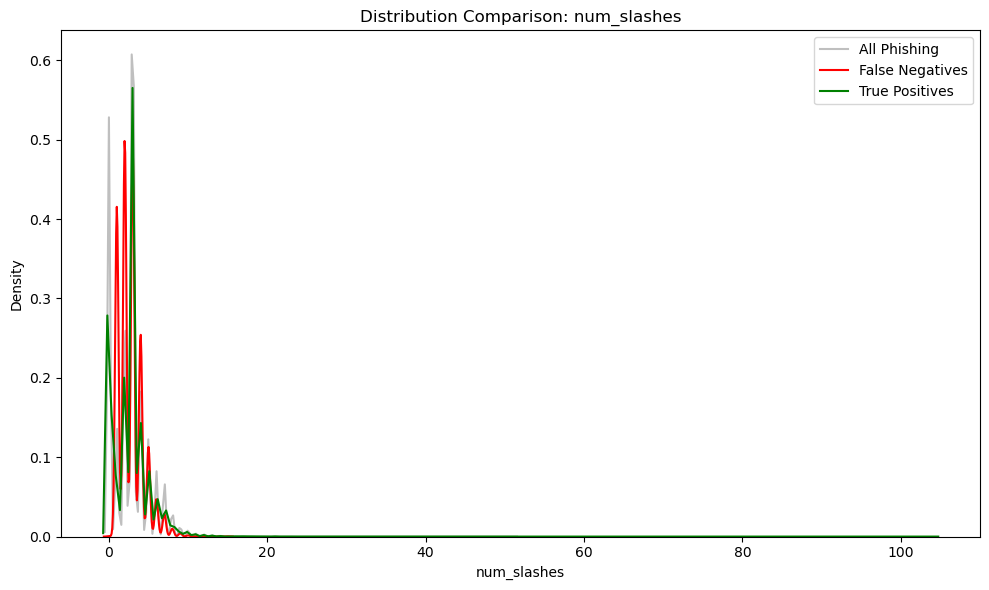

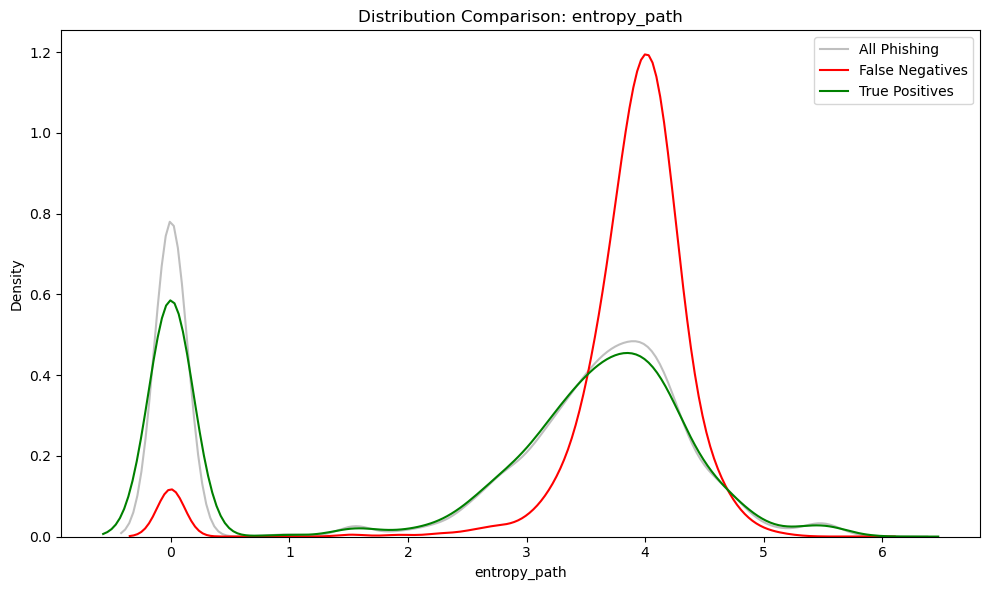

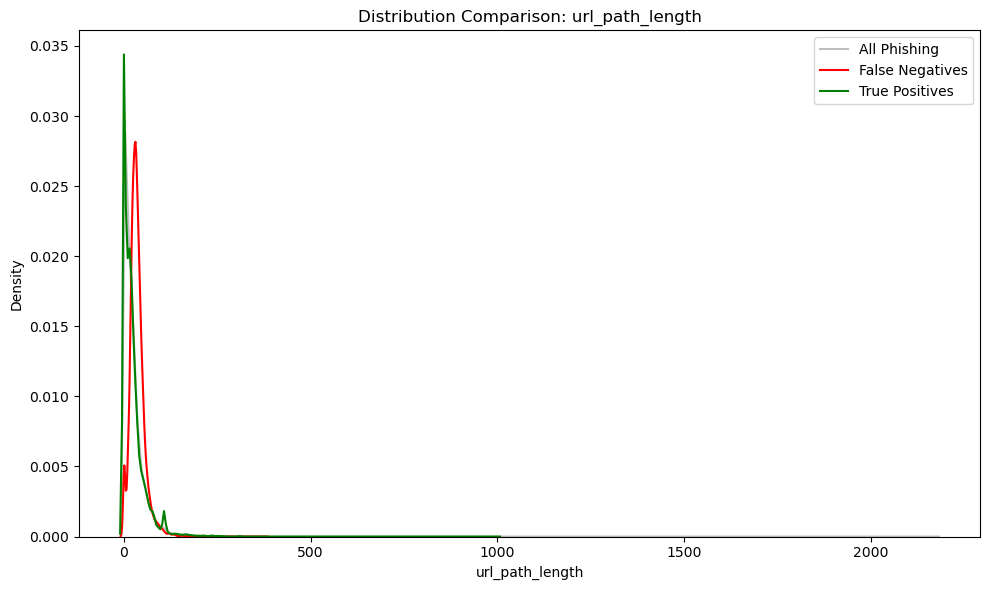

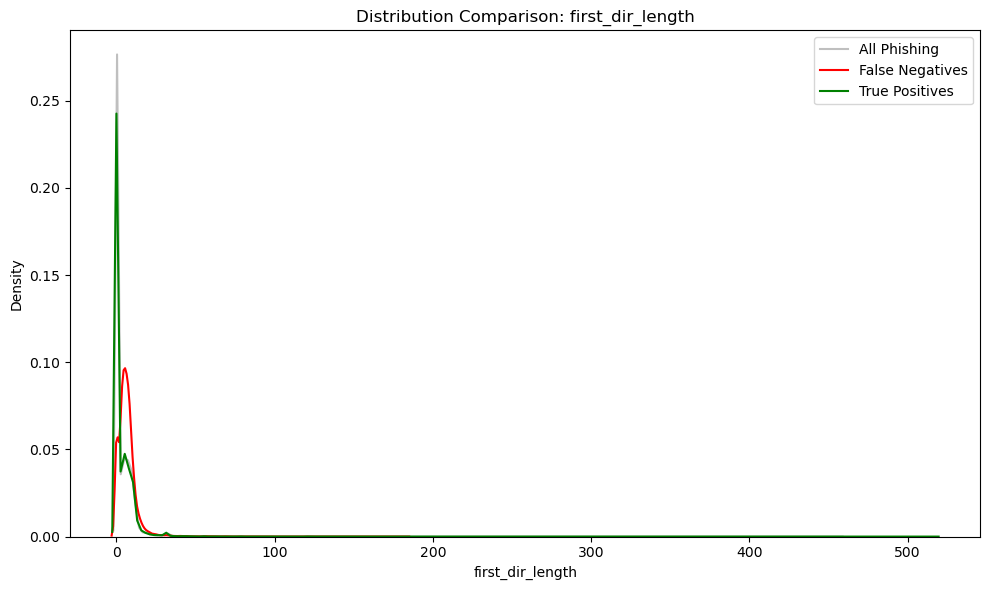

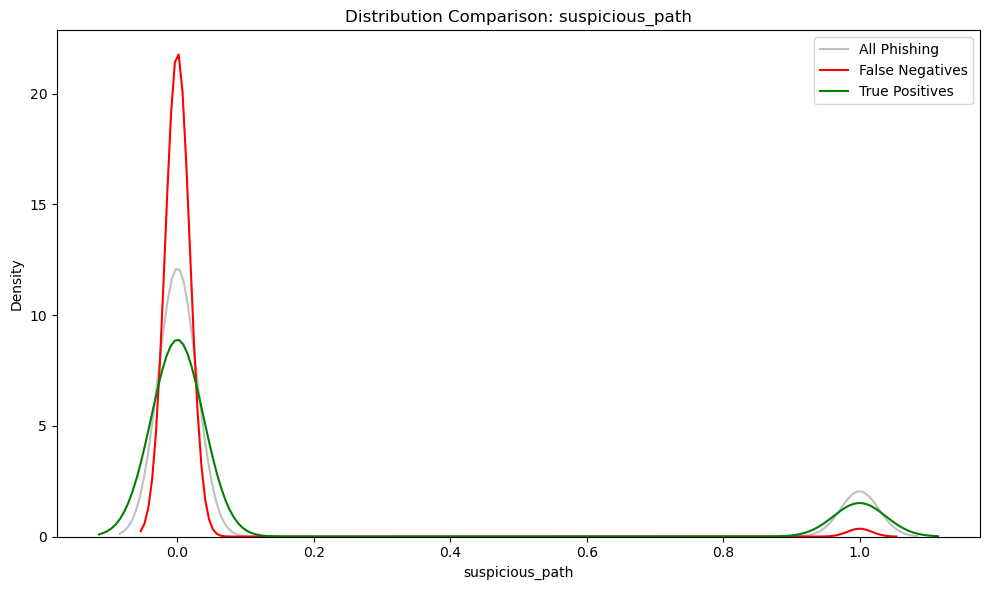

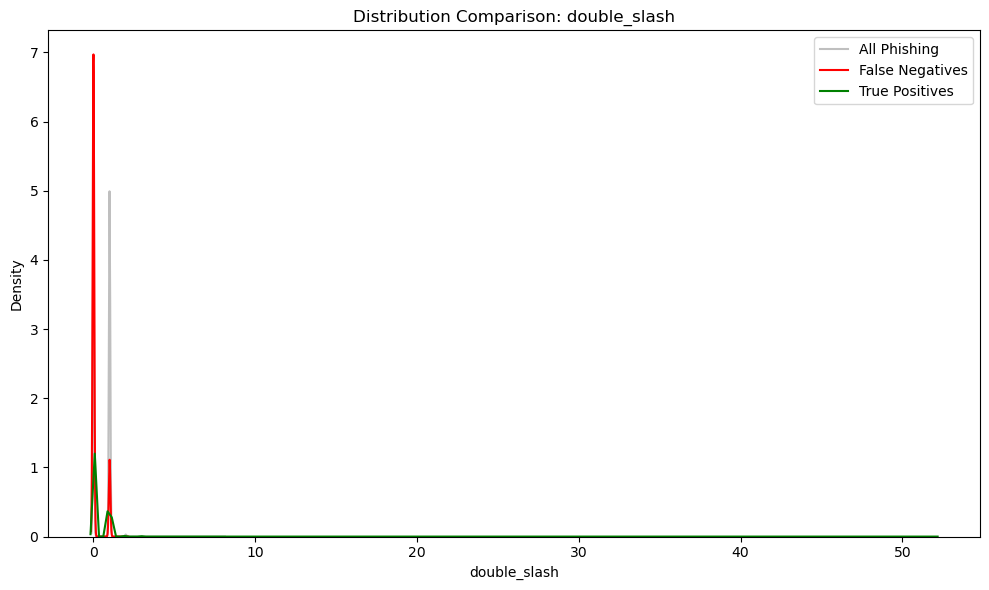

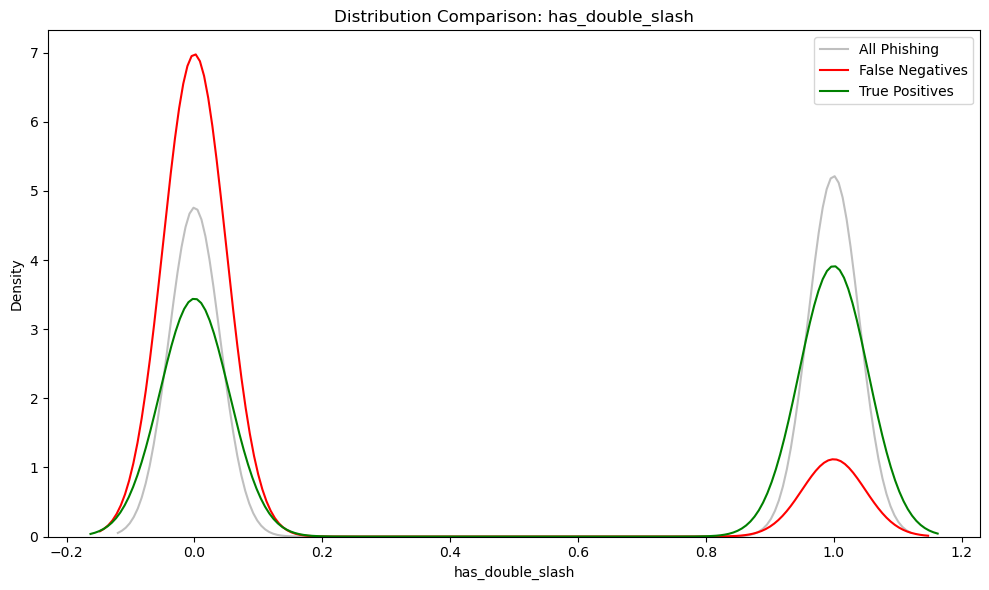

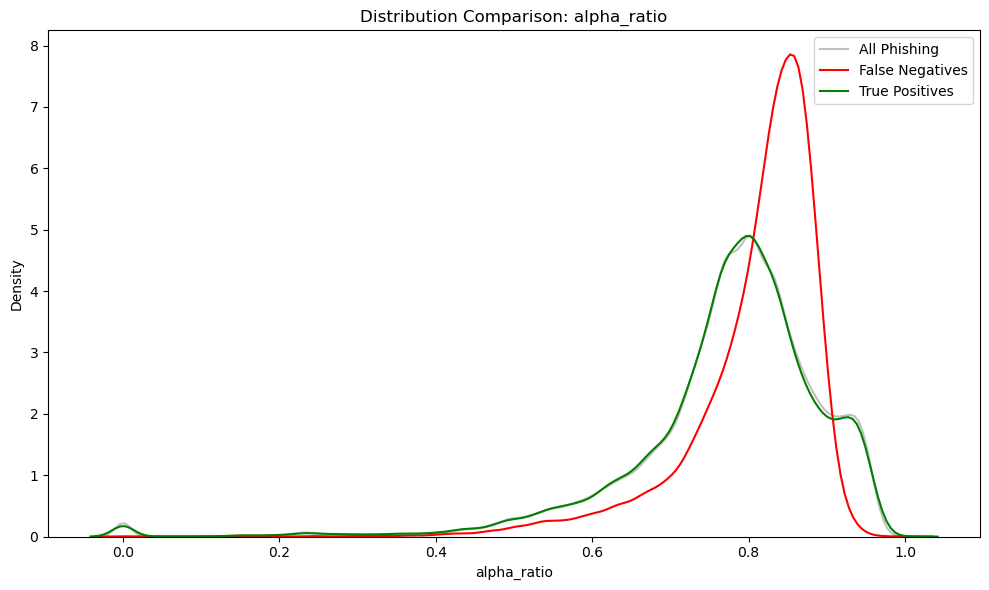

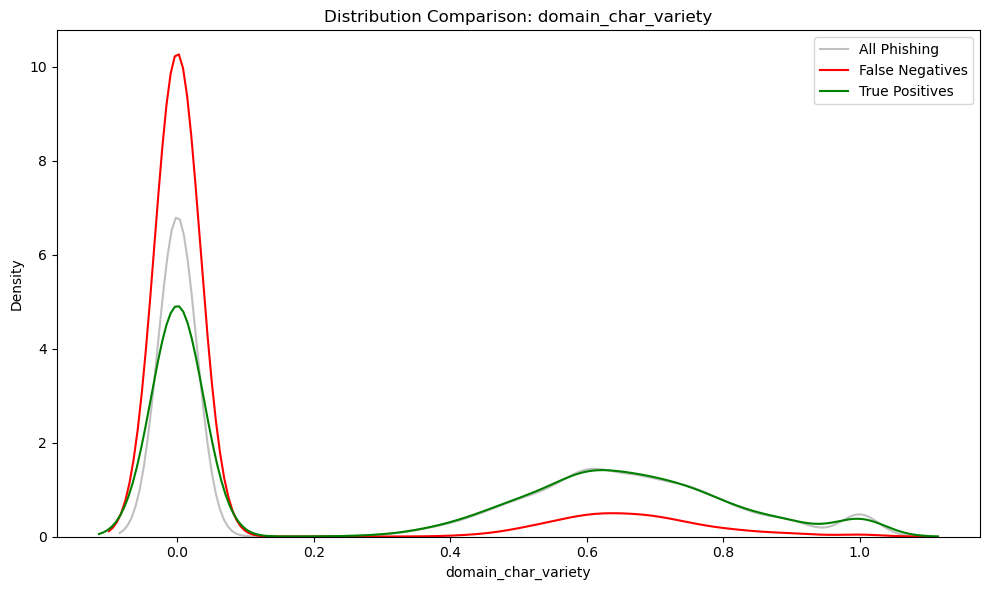

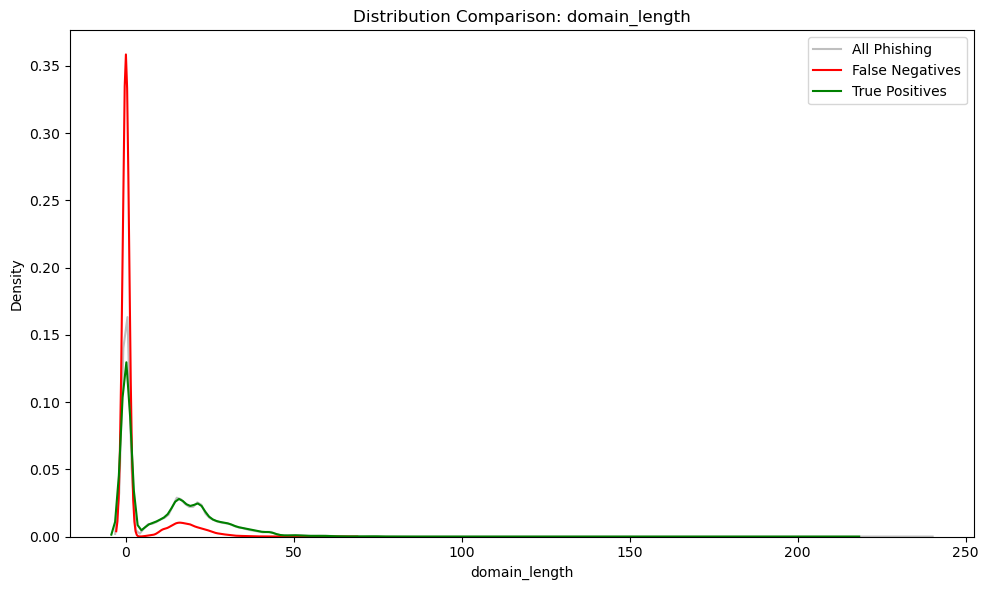

In [17]:
print("False negative analysis")

fn_mask = (y_pred == 0) & (y_test == 1)
fn_data = x_test[fn_mask]
fn_count = fn_mask.sum()

if fn_count > 0:

    def compare_distributions(feature):
        plt.figure(figsize=(10, 6))
  
        phishing_mask = y_train == 1
        if phishing_mask.sum() > 1:
            sns.kdeplot(x_train.loc[phishing_mask, feature], 
                        label='All Phishing', color='grey', alpha=0.5)
    
        if len(fn_data) > 1:
            sns.kdeplot(fp_data[feature], label='False Negatives', color='red')
  
        tp_mask = (y_pred == 1) & (y_test == 1)
        tp_data = x_test[tp_mask]
        if len(tp_data) > 1:
            sns.kdeplot(tp_data[feature], label='True Positives', color='green')
        
        plt.title(f'Distribution Comparison: {feature}')
        plt.legend()
        plt.tight_layout()
        plt.savefig(f'finetuned_fn_distribution_{feature.replace("/", "_")}.png')
        plt.show()

    for feature in importance_df['Feature'].head(10):
        compare_distributions(feature)

#### 5. Partial Dependence Plots (PDPs) for False Negatives

PDPs for FNs
compatible features: 6/10


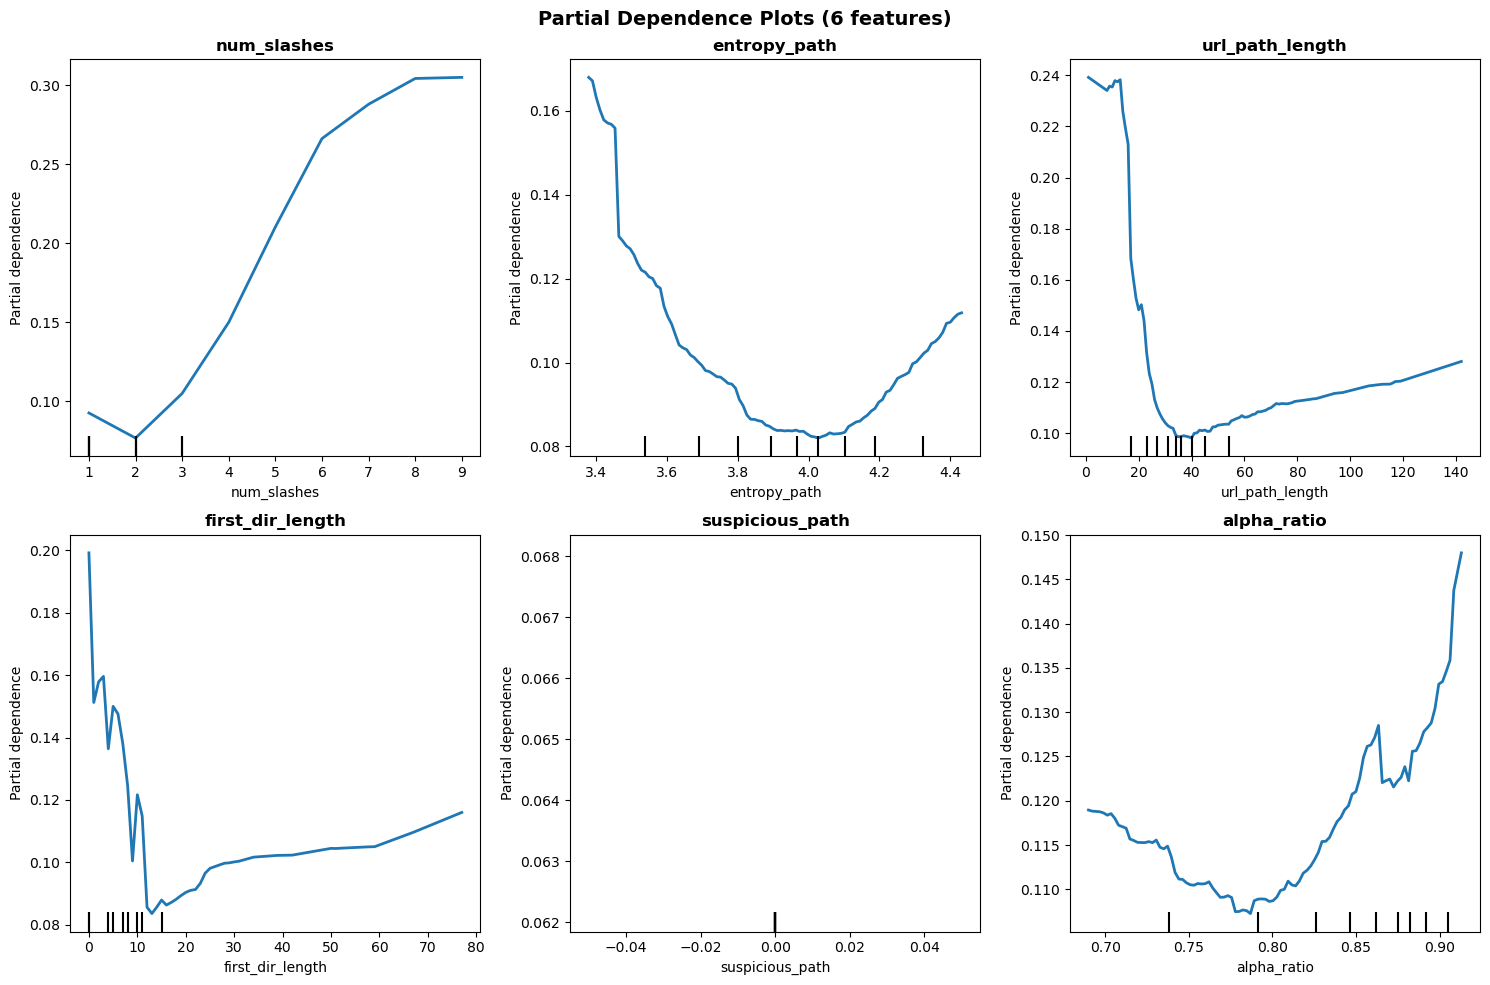

In [18]:
print("PDPs for FNs")

def is_pdp_safe(model, X, feature_name):
    try:
        from sklearn.inspection import partial_dependence
        feature_idx = list(X.columns).index(feature_name)
        partial_dependence(model, X.iloc[:50], features=[feature_idx])
        return True
    except:
        return False

fn_mask = (y_pred == 0) & (y_test == 1)
x_test_fn = x_test[fn_mask]

top_features = importance_df.Feature.head(10).tolist()
pdp_features = [f for f in top_features if is_pdp_safe(loaded_model, x_test_fn, f)]

print(f"compatible features: {len(pdp_features)}/{len(top_features)}")
if not pdp_features:
    print("No compatible features")
    exit()

n_features = len(pdp_features)
n_cols = 3
n_rows = (n_features + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5*n_rows))
if n_features == 1:
    axes = [axes]
elif n_rows == 1:
    axes = axes.reshape(1, -1)
axes = axes.flatten()

for i, feature in enumerate(pdp_features):
    PartialDependenceDisplay.from_estimator(
        loaded_model,
        x_test_fn,
        features=[feature],
        ax=axes[i],
        line_kw={'linewidth': 2}
    )
    axes[i].set_title(f'{feature}', fontweight='bold')
    axes[i].grid(True, alpha=0.3)

for i in range(n_features, len(axes)):
    axes[i].set_visible(False)

plt.suptitle(f'Partial Dependence Plots ({n_features} features)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('finetuned_fn_pdp_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

#### 6. SHAP Analysis for False Positives

SHAP for FPs


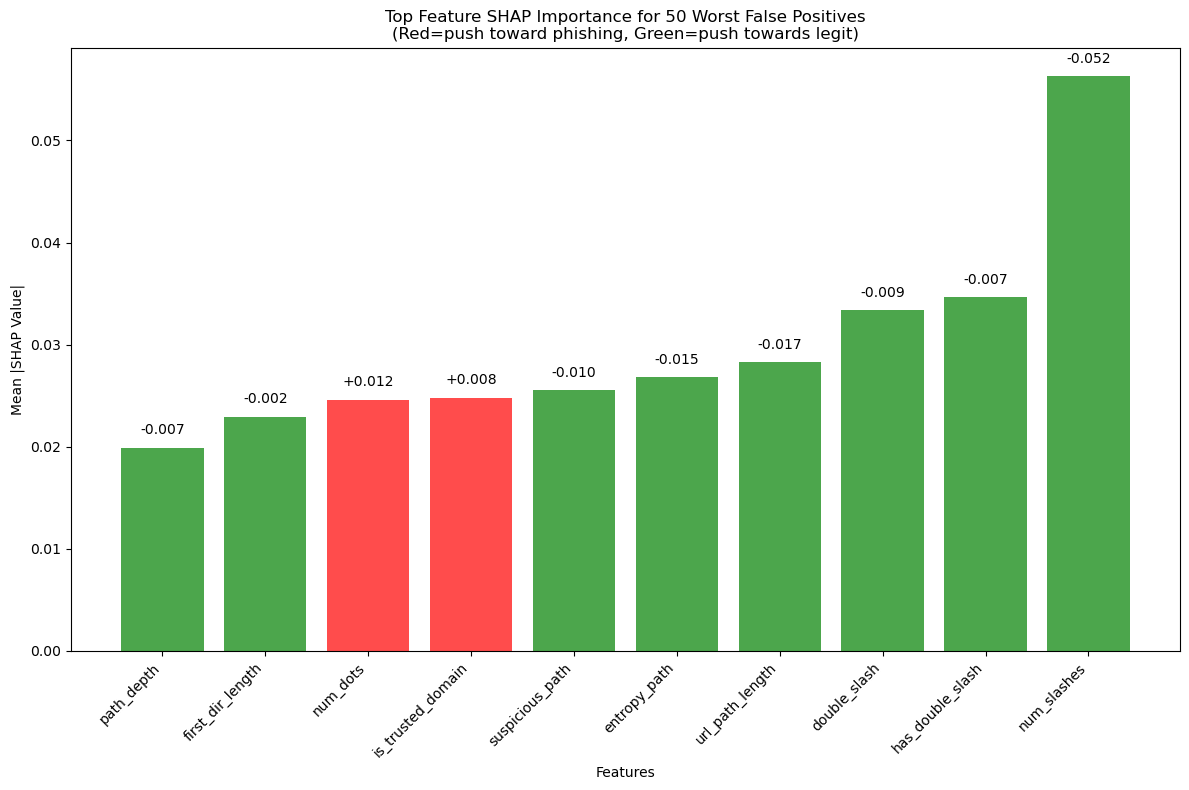

In [19]:
print("SHAP for FPs")
fp_mask = (y_pred == 1) & (y_test == 0)
fp_data = x_test[fp_mask]

if len(fp_data) == 0:
    print("No false positives")
    raise SystemExit

fp_indices = np.where(fp_mask)[0]
fp_probs = y_proba[fp_indices]

samples = min(50, len(fp_indices)) 

# test on a sample of highest confidence FPs
worst_fp_indices = fp_indices[np.argsort(fp_probs)[-samples:]]
worst_fp_data = x_test.iloc[worst_fp_indices]

model = loaded_model

explainer = shap.TreeExplainer(
        model, 
        feature_perturbation='tree_path_dependent',
        model_output='raw'
    )

shap_values_fp = explainer.shap_values(worst_fp_data)

# handle different SHAP formats
if isinstance(shap_values_fp, list):
    shap_values_fp_class1 = shap_values_fp[1]  
else:
    shap_values_fp_class1 = shap_values_fp


if shap_values_fp_class1.ndim == 3:
    shap_values_fp_class1 = shap_values_fp_class1[:, :, 1]
 

mean_abs_shap_fp = np.abs(shap_values_fp_class1).mean(axis=0)
feature_names_fp = worst_fp_data.columns.tolist()

# get top 10 important features for FPs
top_feature_indices_fp = np.argsort(mean_abs_shap_fp)[-10:]
top_features_fp = [feature_names_fp[i] for i in top_feature_indices_fp]
top_shap_values_fp = shap_values_fp_class1[:, top_feature_indices_fp]

plt.figure(figsize=(12, 8))
mean_shap_fp_top = top_shap_values_fp.mean(axis=0)
mean_abs_shap_fp_top = np.abs(top_shap_values_fp).mean(axis=0)

# Bars' colours
colors = ['red' if x > 0 else 'green' for x in mean_shap_fp_top]
bars = plt.bar(range(len(top_features_fp)), mean_abs_shap_fp_top, color=colors, alpha=0.7)

for i, (bar, val) in enumerate(zip(bars, mean_shap_fp_top)):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
             f'{val:+.3f}', ha='center', va='bottom', fontsize=10)

plt.xlabel('Features')
plt.ylabel('Mean |SHAP Value|')
plt.title(f'Top Feature SHAP Importance for {samples} Worst False Positives\n(Red=push toward phishing, Green=push towards legit)')
plt.xticks(range(len(top_features_fp)), top_features_fp, rotation=45, ha='right')
plt.tight_layout()
plt.savefig('finetuned_fp_shap_importance.png', dpi=300, bbox_inches='tight')
plt.show()

#### 7. SHAP Analysis for False Negatives

SHAP for FNs


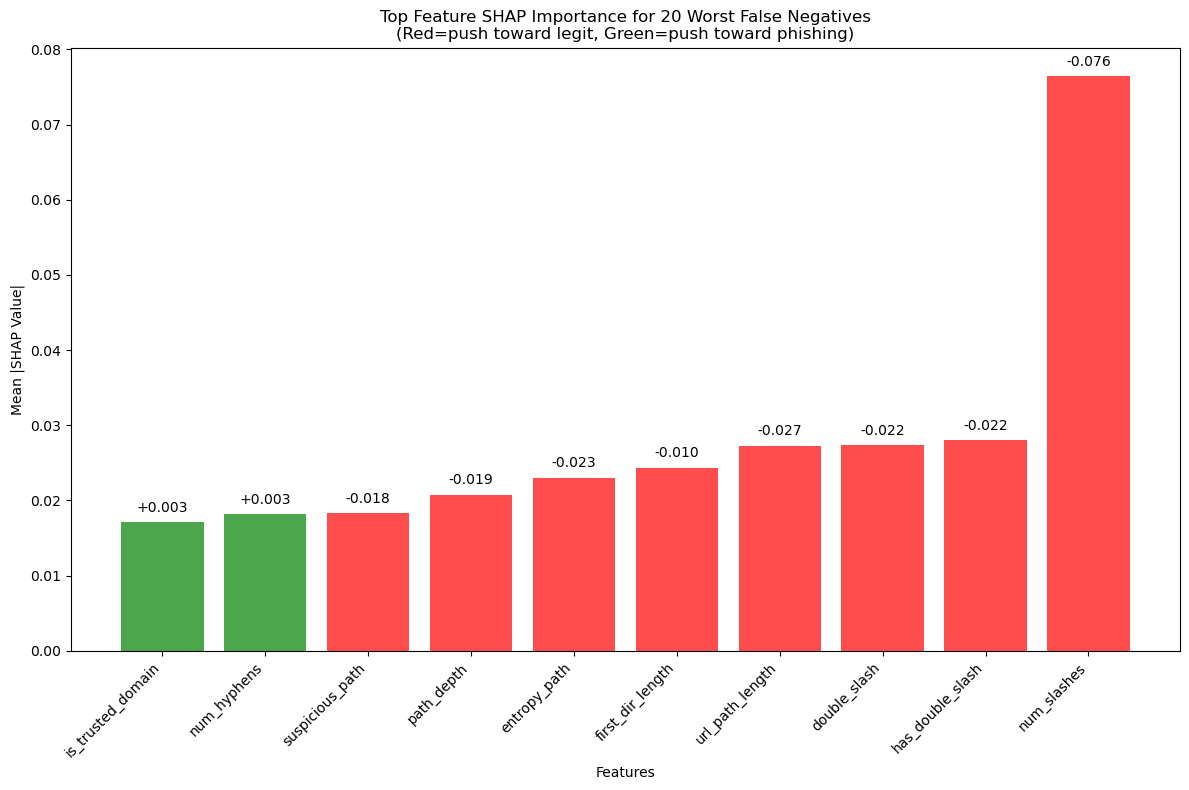

In [15]:
print("SHAP for FNs")
fn_mask = (y_pred == 0) & (y_test == 1)
fn_data = x_test[fn_mask]

if len(fn_data) == 0:
    print("No false negatives")
    raise SystemExit

fn_indices = np.where(fn_mask)[0]
fn_probs = y_proba[fn_indices]

samples = min(20, len(fn_indices)) 

# test on a sample of lowest confidence FNs 
worst_fn_indices = fn_indices[np.argsort(fn_probs)[:samples]]
worst_fn_data = x_test.iloc[worst_fn_indices]

model = loaded_model

explainer = shap.TreeExplainer(
        model, 
        feature_perturbation='tree_path_dependent',
        model_output='raw'
    )

shap_values_fn = explainer.shap_values(worst_fn_data)
        
# handle different SHAP formats
if isinstance(shap_values_fn, list):
    shap_values_fn_class1 = shap_values_fn[1]  
else:
    shap_values_fn_class1 = shap_values_fn

if shap_values_fn_class1.ndim == 3:  
    shap_values_fn_class1 = shap_values_fn_class1[:, :, 1]

mean_abs_shap_fn = np.abs(shap_values_fn_class1).mean(axis=0)
feature_names_fn = worst_fn_data.columns.tolist()

# get top 10 important features for FNs
top_feature_indices_fn = np.argsort(mean_abs_shap_fn)[-10:]
top_features_fn = [feature_names_fn[i] for i in top_feature_indices_fn]
top_shap_values_fn = shap_values_fn_class1[:, top_feature_indices_fn]

plt.figure(figsize=(12, 8))
mean_shap_fn_top = top_shap_values_fn.mean(axis=0)
mean_abs_shap_fn_top = np.abs(top_shap_values_fn).mean(axis=0)

# Bars' colours
colors = ['red' if x < 0 else 'green' for x in mean_shap_fn_top]
bars = plt.bar(range(len(top_features_fn)), mean_abs_shap_fn_top, color=colors, alpha=0.7)
for i, (bar, val) in enumerate(zip(bars, mean_shap_fn_top)):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
             f'{val:+.3f}', ha='center', va='bottom', fontsize=10)

plt.xlabel('Features')
plt.ylabel('Mean |SHAP Value|')
plt.title(f'Top Feature SHAP Importance for {samples} Worst False Negatives\n(Red=push toward legit, Green=push toward phishing)')
plt.xticks(range(len(top_features_fn)), top_features_fn, rotation=45, ha='right')
plt.tight_layout()
plt.savefig('finetuned_fn_shap_importance.png', dpi=300, bbox_inches='tight')
plt.show()

In [21]:
def classify_url_enhanced(url, model=loaded_model, trusted_domains=trusted_domains_set, feature_extractor=extract_features_vectorized):
    
    LOWER_THRESHOLD = 0.1
    UPPER_THRESHOLD = 0.6355
    
    try:
        url_df = pd.DataFrame({'url': [url]})
        features = feature_extractor(url_df['url'], trusted_domains)
        
        is_trusted = features['is_trusted_domain'].iloc[0] == 1
        
        if is_trusted:
            proba = 0.01
            decision = "legitimate"
            confidence = "high"
        else:
            proba = model.predict_proba(features)[0, 1]
            
            if proba <= LOWER_THRESHOLD:
                decision = "legitimate"
                confidence = "high" if proba <= 0.05 else "medium"
            elif proba >= UPPER_THRESHOLD:
                decision = "phishing" 
                confidence = "high" if proba >= 0.8 else "medium"
            else:
                decision = "human_review"
                confidence = "uncertain"
        
        return {
            "url": url,
            "decision": decision,
            "probability": round(proba, 4),
            "confidence": confidence,
            "thresholds": {"lower": LOWER_THRESHOLD, "upper": UPPER_THRESHOLD}
        }
        
    except Exception as e:
        return {"error": f"Classification failed: {str(e)}"}

test_urls = [
    "https://google.com",
    "https://www.google.com/search?q=test", 
    "https://github.com/user/repo",
    "http://suspicious-site-12345.com/login.php",
    "https://microsoft.com",
    "https://phishing-attempt.com/fake-bank-login",
    "https://www.xerblade.com/p/detective-conan-important-episode-list.html?m=0"
]

print("Results:")

for test_url in test_urls:
    result = classify_url_enhanced(test_url)
    if "error" not in result:
        print(f"{result['decision']:<12} | {result['probability']:<6} | {test_url[:40]}...")
    else:
        print(f"Error: {result['error']}")
        break

# Update classification function
classify_url = classify_url_enhanced

Results:
legitimate   | 0.01   | https://google.com...
legitimate   | 0.01   | https://www.google.com/search?q=test...
legitimate   | 0.01   | https://github.com/user/repo...
phishing     | 0.9927 | http://suspicious-site-12345.com/login.p...
legitimate   | 0.01   | https://microsoft.com...
phishing     | 0.852  | https://phishing-attempt.com/fake-bank-l...
phishing     | 0.6822 | https://www.xerblade.com/p/detective-con...
